# Customer Segmentation — Mall Customers Dataset

K-means on the classic Mall Customers dataset (200 rows, columns: Age, Annual Income, Spending Score, plus Gender). Goal: find clusters that a marketing team could actually use — high-income low-spenders, young splurgers, etc. PCA at the end so the segments are easy to look at.

200 rows is too few to take K-means seriously as a generalizable model, but it's a useful demo of the workflow.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

np.random.seed(42)
DATA_DIR = Path("../../data/mall_customers")
CSV = DATA_DIR / "Mall_Customers.csv"
# public mirror of the Mall Customers CSV (the copy used in the Machine Learning A-Z course)
URL = ("https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/"
       "Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/"
       "Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv")
if not CSV.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV)
df = pd.read_csv(CSV).rename(columns={"Genre": "Gender"})
print(df.shape)
df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## EDA

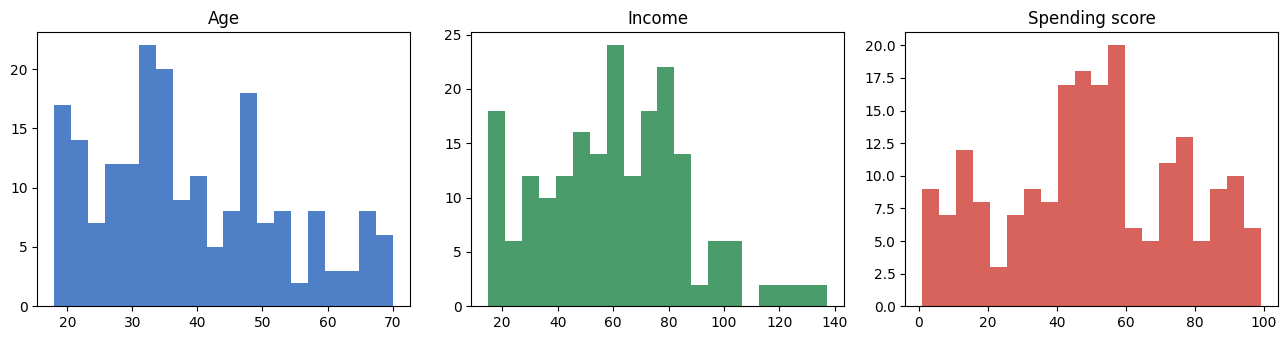

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(df["Age"], bins=20, color="#4f7fc7"); axes[0].set_title("Age")
axes[1].hist(df["Annual Income (k$)"], bins=20, color="#4a9c6a"); axes[1].set_title("Income")
axes[2].hist(df["Spending Score (1-100)"], bins=20, color="#d8625c"); axes[2].set_title("Spending score")
plt.tight_layout(); plt.show()


## Choosing k — elbow + silhouette

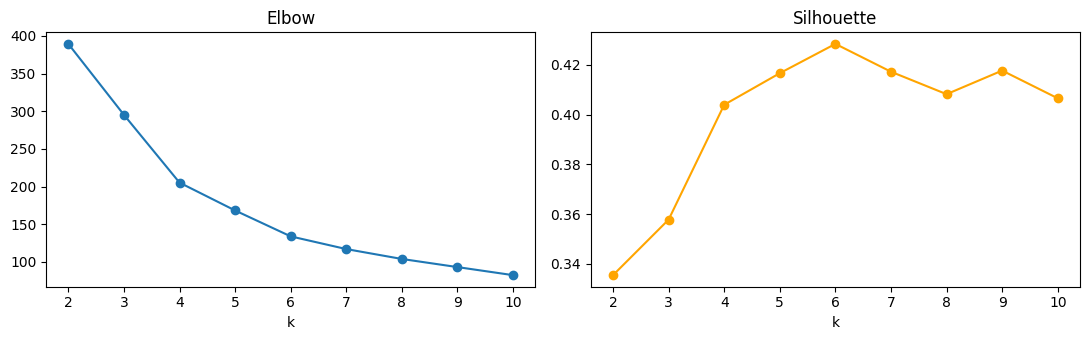

chosen k = 6


In [3]:
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(df[features].values)

inertias, sils = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Elbow"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sils, "o-", color="orange"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# the elbow plot looks ambiguous so I'm picking the k that maximizes silhouette
best_k = list(ks)[int(np.argmax(sils))]
print(f"chosen k = {best_k}")


In [4]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(X)
df["cluster"] = km.labels_

# cluster profiles
print(df.groupby("cluster")[features].mean().round(1))
print()
print("cluster sizes:")
print(df["cluster"].value_counts().sort_index())


          Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                  
0        41.9                88.9                    17.0
1        56.3                54.3                    49.1
2        25.2                25.8                    76.9
3        32.7                86.5                    82.1
4        26.7                57.6                    47.8
5        45.5                26.3                    19.4

cluster sizes:
cluster
0    33
1    45
2    24
3    39
4    38
5    21
Name: count, dtype: int64


## PCA visualization

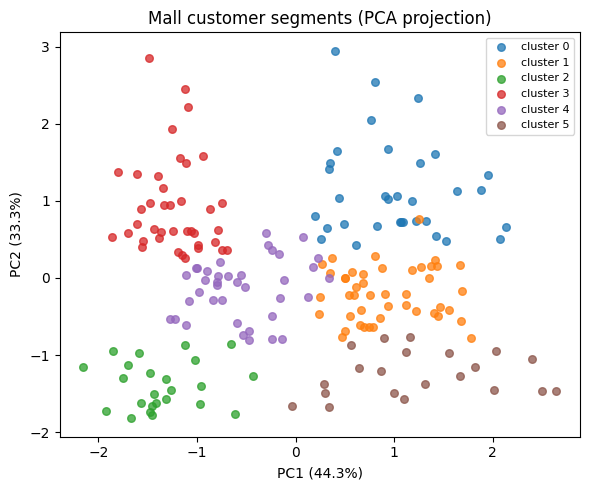

In [5]:
pca = PCA(n_components=2)
Xp = pca.fit_transform(X)

plt.figure(figsize=(6, 5))
for c in sorted(df["cluster"].unique()):
    mask = df["cluster"] == c
    plt.scatter(Xp[mask, 0], Xp[mask, 1], label=f"cluster {c}", alpha=0.75, s=30)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(fontsize=8)
plt.title("Mall customer segments (PCA projection)")
plt.tight_layout(); plt.show()


## Takeaways

On the real 200-row file, silhouette picks k = 6, and the six segments read as plausible personas:

- High income, high spend (about 33 years old on average, the prime target)
- High income, low spend (around 42, potential to convert)
- Low income, high spend (the youngest group, about 25)
- Low income, low spend (around 45)
- Two mid income, mid spend groups that differ mainly by age (about 27 vs about 56)

The two mid-income groups are the only split I'd question. With income and spend alone the data usually lands on 5 clusters, and adding age is what pulls the middle apart. For a real marketing use I'd check that the segments stay stable across resampling before promising anyone anything.